### **UNSW-NB15: XGBoost Hyperparameter Tuning**
##### Target: label (0 = Normal, 1 = Attack)

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

### **1. Configuration**

In [7]:
RANDOM_STATE = 42
TARGET = "label"

# Project paths
CURRENT_DIR = Path.cwd()

# Locate project and capstone directories
if CURRENT_DIR.name == "capstone":
    CAPSTONE_DIR = CURRENT_DIR
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR
    CAPSTONE_DIR = PROJECT_DIR / "capstone"

DATASET_DIR = PROJECT_DIR / "dataset"
RESULTS_DIR = CAPSTONE_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Results directory:", RESULTS_DIR)

Project directory: c:\PK\Projects\network-intrusion
Dataset directory: c:\PK\Projects\network-intrusion\dataset
Results directory: c:\PK\Projects\network-intrusion\capstone\results


### **2. Load Dataset**

In [8]:
print("\nLoading datasets...")

df_train = pd.read_parquet(DATASET_DIR / "train_full.parquet")
df_test = pd.read_parquet(DATASET_DIR / "test_full.parquet")

print("Training shape:", df_train.shape)
print("Testing shape :", df_test.shape)


Loading datasets...
Training shape: (175341, 45)
Testing shape : (82332, 45)


### **3. Separate Features and Target**

In [9]:
# Remove identifiers and target-derived columns if present
DROP_COLUMNS = ["id", "attack_cat", "traffic_type"]

columns_to_drop = [
    col for col in DROP_COLUMNS
    if col in df_train.columns
]

X = df_train.drop(columns=columns_to_drop + [TARGET])
y = df_train[TARGET]

X_test = df_test.drop(
    columns=[col for col in columns_to_drop if col in df_test.columns] + [TARGET]
)
y_test = df_test[TARGET]

print("\nNumber of features:", X.shape[1])


Number of features: 42


### **4. Train-Validation Split**

In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining split:", X_train.shape)
print("Validation split:", X_val.shape)


Training split: (140272, 42)
Validation split: (35069, 42)


### **5. Identify Feature Types**

In [11]:
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))



Numerical features: 39
Categorical features: 3


C:\Users\Prateek\AppData\Local\Temp\ipykernel_9996\1264500848.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


### **6. Preprocessing**

In [12]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numerical_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ]
)


### **7. Define XGBoost Model**

In [13]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=1
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])

### **8. Hyperparameter Search Space**

In [14]:
param_grid = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__gamma": [0, 0.1, 0.3],
    "model__reg_lambda": [1, 3, 5]
}

### **9. Randomized Search with Cross-Validation**

In [15]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=10,
    scoring="f1",
    cv=cv,
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)

print("\nStarting hyperparameter tuning...")

random_search.fit(X_train, y_train)

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(random_search.best_score_, 4))


Starting hyperparameter tuning...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters:
{'model__subsample': 0.8, 'model__reg_lambda': 5, 'model__n_estimators': 300, 'model__min_child_weight': 3, 'model__max_depth': 8, 'model__learning_rate': 0.1, 'model__gamma': 0, 'model__colsample_bytree': 1.0}

Best Cross-Validation F1 Score:
0.9689


### **10. Evaluate Tuned Model on Validation Data**

In [16]:
best_model = random_search.best_estimator_

y_val_pred = best_model.predict(X_val)
y_val_prob = best_model.predict_proba(X_val)[:, 1]

print("\n" + "=" * 60)
print("VALIDATION PERFORMANCE")
print("=" * 60)

print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall   :", recall_score(y_val, y_val_pred))
print("F1 Score :", f1_score(y_val, y_val_pred))
print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob))
print("PR-AUC   :", average_precision_score(y_val, y_val_prob))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))


VALIDATION PERFORMANCE
Accuracy : 0.9599931563489121
Precision: 0.9648266159066456
Recall   : 0.976831873978801
F1 Score : 0.9707921307380035
ROC-AUC  : 0.9940347069270961
PR-AUC   : 0.9971720010886701

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.92      0.94     11200
           1       0.96      0.98      0.97     23869

    accuracy                           0.96     35069
   macro avg       0.96      0.95      0.95     35069
weighted avg       0.96      0.96      0.96     35069



### **11. Train Final Model on Complete Training Dataset**

In [18]:
print("\nTraining final model on complete training dataset...")

best_model.fit(X, y)


Training final model on complete training dataset...


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['dur','proto','service',...,'ct_src_ltm','ct_srv_dst','is_sm_ips_ports']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, al

### **12. Final Evaluation on Test Dataset**

In [17]:
y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1 Score": f1_score(y_test, y_test_pred),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "PR-AUC": average_precision_score(y_test, y_test_prob)
}

print("\n" + "=" * 60)
print("FINAL TEST PERFORMANCE")
print("=" * 60)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))


FINAL TEST PERFORMANCE
Accuracy: 0.8730
Precision: 0.8207
Recall: 0.9844
F1 Score: 0.8951
ROC-AUC: 0.9845
PR-AUC: 0.9886

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.74      0.84     37000
           1       0.82      0.98      0.90     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.87     82332
weighted avg       0.89      0.87      0.87     82332



### **13. Confusion Matrix**

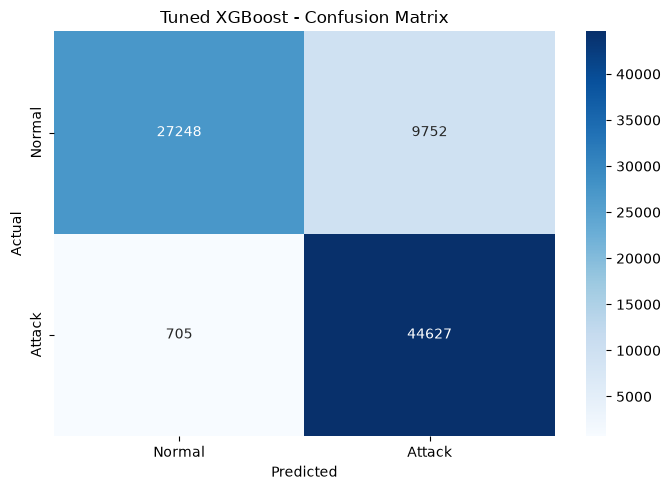

In [19]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.title("Tuned XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "tuned_xgboost_confusion_matrix.png",
    dpi=300
)

plt.show()


### **14. Feature Importance**

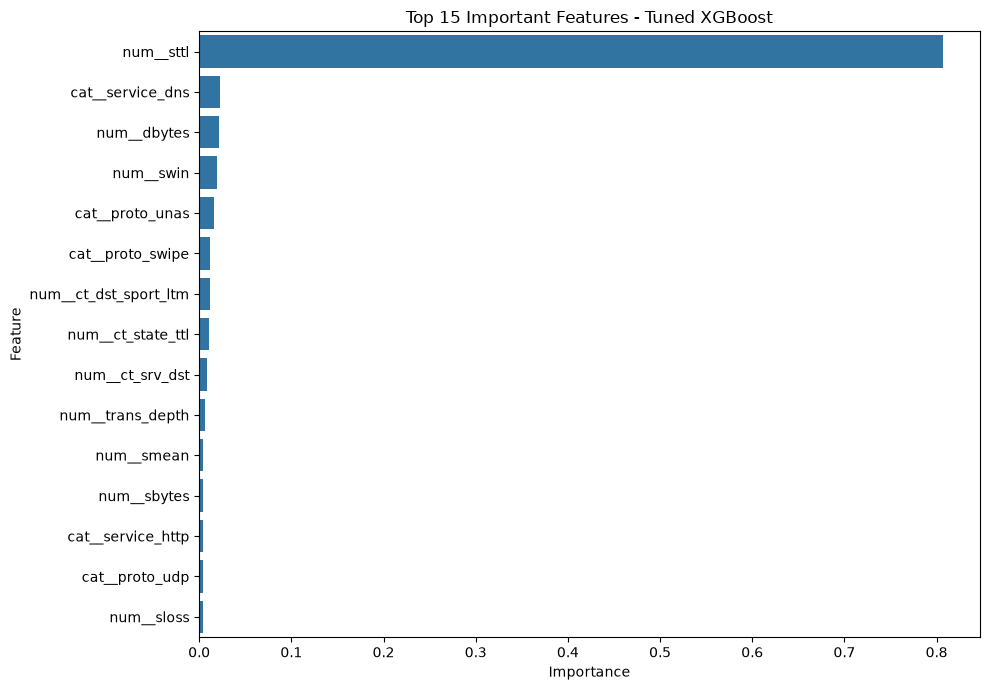

In [20]:
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_values = best_model.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.to_csv(
    RESULTS_DIR / "tuned_xgboost_feature_importance.csv",
    index=False
)

top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Tuned XGBoost")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "tuned_xgboost_feature_importance.png",
    dpi=300
)

plt.show()


### **15. Final Summary**

In [21]:
print("\n" + "=" * 60)
print("HYPERPARAMETER TUNING COMPLETED")
print("=" * 60)

print("Best CV F1 Score:", round(random_search.best_score_, 4))
print("Final Test F1 Score:", round(test_metrics["F1 Score"], 4))


HYPERPARAMETER TUNING COMPLETED
Best CV F1 Score: 0.9689
Final Test F1 Score: 0.8951


In [24]:
joblib.dump(
    best_model,
    RESULTS_DIR / "best_xgb_pipeline.joblib"
)

with open(RESULTS_DIR / "best_xgb_params.json", "w") as file:
    json.dump(random_search.best_params_, file, indent=4)

pd.DataFrame(
    [test_metrics]
).to_csv(
    RESULTS_DIR / "tuned_xgboost_test_metrics.csv",
    index=False
)